# 05 - Let's test it!

**Business Loves Uplift: Causal Impact Evaluation With Python**<br>
ODSC AI West 2026 · Alex Molak · [CausalPython.io](https://causalpython.io)

<a href="https://colab.research.google.com/github/AlxndrMlk/talks-and-workshops/blob/main/2026-10--odsc-ai/05%20-%20Triangulation.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>


**The story.** A retailer's field sales reps each look after 120-200 stores. The data team built a recommender that tells a rep which new products (SKUs) to list in each store. How much does it lift store sales?

The data is synthetic, so we know the true answer. Weekly sales are in k$ per store.

We have three estimates: the clustered A/B test, DML and synthetic control. Each method can fail, sometimes in a different way. In this notebook we put the three side by side, run each through a stress test where the true answer is zero, and only then compare them with the truth.

In [14]:
# Colab only: install the packages and get the data generator (locally, use the workshop env)
import sys
if "google.colab" in sys.modules:
    !pip install -q dowhy==0.14 econml==0.17.0 cluster-experiments==0.31.0 mlsynth==1.0.0
    !wget -q -nc https://raw.githubusercontent.com/AlxndrMlk/talks-and-workshops/main/2026-10--odsc-ai/uplift_data.py
    !wget -q -nc https://raw.githubusercontent.com/AlxndrMlk/talks-and-workshops/main/2026-10--odsc-ai/dml_data.py

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cluster_experiments import OLSAnalysis, ClusteredOLSAnalysis
from econml.dml import DML
from econml.sklearn_extensions.linear_model import StatsModelsLinearRegression
from mlsynth import VanillaSC
from sklearn.linear_model import LassoCV, LogisticRegressionCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import dml_data as dd
import uplift_data as ud

BLUE, GOLD, GREY, RED, DARK = "#0057d9", "#c8860d", "#bbbbbb", "#c0392b", "#222222"
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})

In [16]:
d = ud.make_datasets()     # seed 23: everyone gets the same world
truth = d["truth"]         # the answer key; we only peek at it at the end of each section
print(ud.fingerprint(d))   # should print 13302.553/5496.520

d_dml = dd.make_datasets()  # the DML study has its own data
truth_dml = d_dml["truth"]

13302.553/5496.520


## Three methods, three numbers

The same estimators as in notebooks 02-04, reported in % of sales without the recommender.

The A/B test and synthetic control use the same data. DML comes from a different study, with its own data, in which management chose who got the recommender. So each number has its own truth.

In [17]:
# clustered A/B test with CUPED (notebook 02)
ab = d["ab_rep"]
r = ClusteredOLSAnalysis(cluster_cols=["rep_id"], target_col="sales_test", treatment_col="treated", treatment=1,
                         covariates=["sales_pre"]).get_inference_results(ab, alpha=0.05)
base = ab.loc[ab.treated == 0, "sales_test"].mean()
ab_est, ab_lo, ab_hi = r.ate / base, r.conf_int.lower / base, r.conf_int.upper / base

# DML (notebook 03)
def fit_dml(df, y):
    est = DML(model_y=make_pipeline(StandardScaler(), LassoCV()),
              model_t=make_pipeline(StandardScaler(), LogisticRegressionCV(max_iter=2000)),
              model_final=StatsModelsLinearRegression(fit_intercept=False),
              discrete_treatment=True, cv=5, random_state=0)
    x = df[["experience"]]
    est.fit(df[y], df.recommender, X=x, W=df[["experience", "store_size", "footfall"]])
    lo, hi = est.ate_interval(X=x)
    return float(est.ate(X=x)), lo, hi


reps = d_dml["reps_observed"]
ate, lo, hi = fit_dml(reps, "sales_post")
y0 = reps.sales_post.mean() - reps.recommender.mean() * ate   # sales if nobody had the recommender
dml_est, dml_lo, dml_hi = ate / y0, lo / y0, hi / y0

# synthetic control (notebook 04)
rw = d["region_week"]
N_PRE = 52


def fit_sc(df):
    return VanillaSC({"df": df, "outcome": "sales", "treat": "treated", "unitid": "region",
                      "time": "week", "display_graphs": False}).fit()


sc = fit_sc(rw)
synthetic_post = np.asarray(sc.counterfactual)[N_PRE:].mean()
sc_ci = VanillaSC({"df": rw, "outcome": "sales", "treat": "treated", "unitid": "region",
                   "time": "week", "display_graphs": False, "inference": "ttest"}).fit().att_ci
sc_est, sc_lo, sc_hi = sc.att / synthetic_post, sc_ci[0] / synthetic_post, sc_ci[1] / synthetic_post

estimates = pd.DataFrame({
    "estimate": [ab_est, dml_est, sc_est],
    "lo": [ab_lo, dml_lo, sc_lo],
    "hi": [ab_hi, dml_hi, sc_hi],
}, index=["Clustered A/B (CUPED)", "DML", "Synthetic control"])
estimates.style.format("{:.1%}", na_rep="-")

,estimate,lo,hi
Clustered A/B (CUPED),8.8%,6.8%,10.9%
DML,14.6%,12.6%,16.7%
Synthetic control,9.0%,7.3%,11.1%


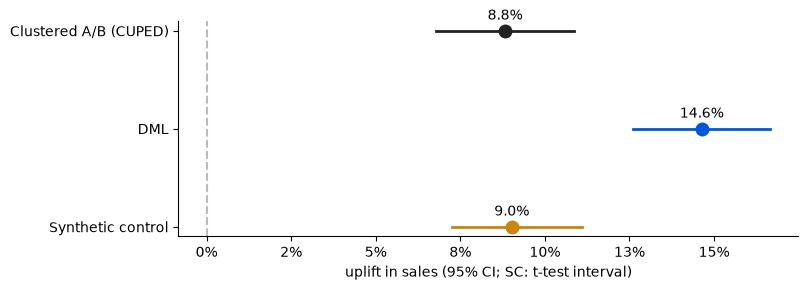

In [18]:
colors = [DARK, BLUE, GOLD]
fig, ax = plt.subplots(figsize=(8, 2.8))
for i, (name, r) in enumerate(estimates.iterrows()):
    if not np.isnan(r.lo):
        ax.plot([r.lo, r.hi], [i, i], color=colors[i], lw=2)
    ax.plot(r.estimate, i, "o", color=colors[i], ms=9)
    ax.annotate(f"{r.estimate:.1%}", (r.estimate, i), xytext=(0, 8), textcoords="offset points", ha="center")
ax.set_yticks(range(3), estimates.index)
ax.invert_yaxis()
ax.axvline(0, color=GREY, ls="--")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("uplift in sales (95% CI; SC: t-test interval)")
plt.show()

Same sign, but DML sits well above the other two, and its interval doesn't overlap theirs. It also comes from a different study. Before we explain the differences, let's see whether each method can recognize a lack of effect when the true effect is null.

## Stress test 1: A/A test

Split the reps into two arms, give nobody the recommender, and test (without CUPED). With a 5% significance level, about 5% of splits should find an "effect". We use the 8 weeks before the A/B test.

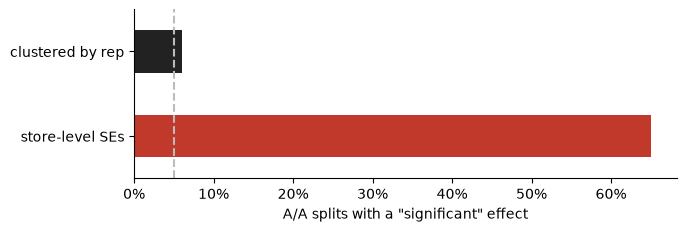

store-level SEs     0.65
clustered by rep    0.06
dtype: float64

In [19]:
history = d["history"]
stores = history.groupby(["store_id", "rep_id"], as_index=False).sales.mean()
all_reps = stores.rep_id.unique()

setup = {"target_col": "sales", "treatment_col": "t", "treatment": 1}
store_level = OLSAnalysis(cov_type="nonrobust", **setup)
by_rep = ClusteredOLSAnalysis(cluster_cols=["rep_id"], **setup)

rng = np.random.default_rng(0)
n_splits, hits_store, hits_rep = 200, 0, 0
for _ in range(n_splits):
    reps_ = rng.choice(all_reps, 40, replace=False)
    df = stores[stores.rep_id.isin(reps_)].assign(t=lambda x: x.rep_id.isin(reps_[:20]).astype(int))
    hits_store += store_level.get_pvalue(df) < 0.05
    hits_rep += by_rep.get_pvalue(df) < 0.05

aa = pd.Series({"store-level SEs": hits_store / n_splits, "clustered by rep": hits_rep / n_splits})
ax = aa.plot.barh(color=[RED, DARK], figsize=(7, 2.2))
ax.axvline(0.05, color=GREY, ls="--")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel('A/A splits with a "significant" effect')
plt.show()
aa

## Stress test 2: DML placebos

Run DML where the answer must be zero:

- **Placebo outcome:** sales *before* the recommender went live (`placebo_observed`). Nobody had it yet.
- **Placebo treatment:** shuffle `recommender` across reps, many times.

In [20]:
plc = d_dml["placebo_observed"]
plc_est, plc_lo, plc_hi = fit_dml(plc, "sales_placebo")

rng = np.random.default_rng(1)
shuffled = []
for _ in range(20):
    df = reps.assign(recommender=rng.permutation(reps.recommender.to_numpy()))
    shuffled.append(fit_dml(df, "sales_post")[0])
shuffled = np.array(shuffled)

dml_tests = pd.DataFrame({
    "estimate (k$)": [ate, plc_est, shuffled.mean()],
    "lo": [lo, plc_lo, np.quantile(shuffled, 0.025)],
    "hi": [hi, plc_hi, np.quantile(shuffled, 0.975)],
}, index=["DML: the real effect", "placebo outcome: sales before the rollout", "placebo treatment: shuffled recommender"])
dml_tests.round(2)

,estimate (k$),lo,hi
DML: the real effect,2.91,2.51,3.32
placebo outcome: sales before the rollout,0.58,0.22,0.94
placebo treatment: shuffled recommender,-0.04,-0.52,0.26


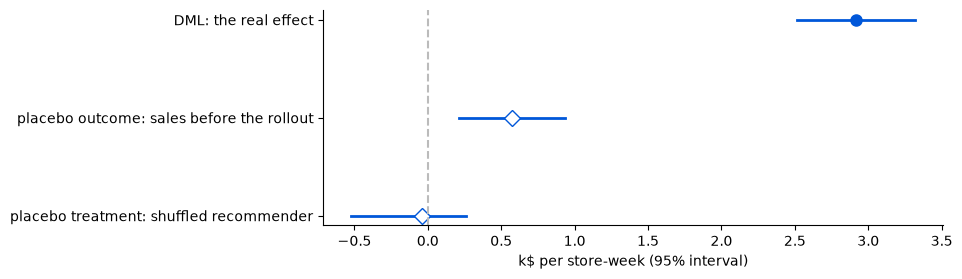

In [21]:
fig, ax = plt.subplots(figsize=(8, 2.8))
for i, (name, r) in enumerate(dml_tests.iterrows()):
    ax.plot([r.lo, r.hi], [i, i], color=BLUE, lw=2)
    ax.plot(r["estimate (k$)"], i, "o" if i == 0 else "D", color=BLUE, ms=8, mfc=BLUE if i == 0 else "white")
ax.set_yticks(range(3), dml_tests.index)
ax.invert_yaxis()
ax.axvline(0, color=GREY, ls="--")
ax.set_xlabel("k$ per store-week (95% interval)")
plt.show()

The shuffled treatment lands on zero, as it should. **The placebo outcome doesn't.** DML finds an "effect" of the recommender on sales from *before* the recommender existed. Something we don't adjust for might be raising the sales of the reps who got the recommender, even before they had it. This can be an indication of a hidden confounder.

This is congruent with sensitivity analysis results in notebook 03: a hidden confounder as strong as experience could bias the estimate by roughly 0.4-0.5 k\$. One 3x as strong would leave the effect above 1 k\$. The placebo result is congruent with the hypothesis that a hidden confounder exists in our problem.

## Stress test 3: SC with a fake rollout date

Move the rollout 20 weeks into the pre-period and fit only on the weeks before it. No gap should open until the real rollout.

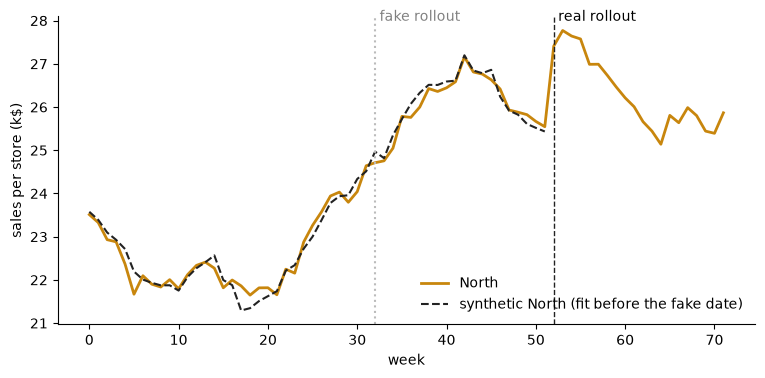

gap after the fake date: -0.06 k$ (the real estimate is 2.18 k$)


In [22]:
FAKE = N_PRE - 20
df_fake = rw[rw.week < N_PRE].copy()
df_fake["treated"] = ((df_fake.region == "North") & (df_fake.week >= FAKE)).astype(int)
sc_fake = fit_sc(df_fake)

panel = rw.pivot(index="week", columns="region", values="sales")
plt.plot(panel.index, panel.North, color=GOLD, lw=2, label="North")
plt.plot(range(N_PRE), sc_fake.counterfactual, color=DARK, ls="--", label="synthetic North (fit before the fake date)")
plt.axvline(FAKE, color=GREY, ls=":")
plt.axvline(N_PRE, color=DARK, ls="--", lw=1)
plt.text(FAKE + 0.5, panel.values.max(), "fake rollout", va="top", color="gray")
plt.text(N_PRE + 0.5, panel.values.max(), "real rollout", va="top")
plt.xlabel("week")
plt.ylabel("sales per store (k$)")
plt.legend(frameon=False, loc="lower right")
plt.show()
print(f"gap after the fake date: {sc_fake.att:.2f} k$ (the real estimate is {sc.att:.2f} k$)")

## Stress test 4: SC with fake Norths

Run SC for every other region as if it got the recommender (the real North is excluded as a donor). We rank regions by post/pre RMSE ratio: with 8 regions, the best p-value we can get is 1/8.

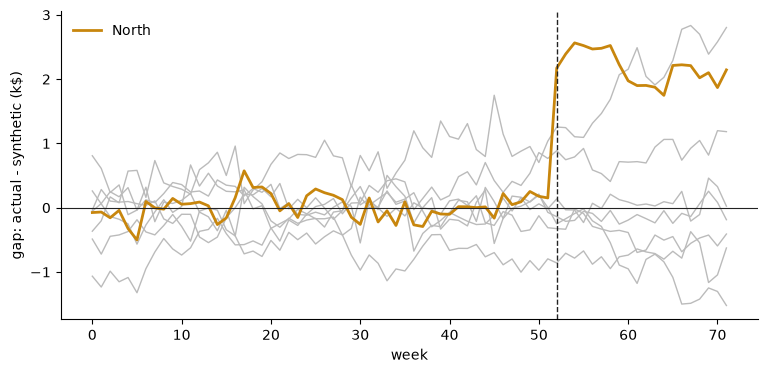

North ranks 1 of 8, rank p-val = 0.125


North        11.1
South         3.6
Coast         2.7
Highlands     2.1
Central       1.5
East          1.2
Lakes         0.9
West          0.6
dtype: float64

In [23]:
gaps, ratios = {}, {}
for region in ud.REGIONS:
    if region == "North":
        df = rw
    else:   # the fake North takes the North's place; the real North is left out
        df = rw[rw.region != "North"].copy()
        df["treated"] = ((df.region == region) & (df.week >= N_PRE)).astype(int)
    fit_r = fit_sc(df)
    actual = df[df.region == region].sort_values("week").sales.to_numpy()
    gap = actual - np.asarray(fit_r.counterfactual)
    gaps[region] = gap
    ratios[region] = np.sqrt((gap[N_PRE:] ** 2).mean()) / np.sqrt((gap[:N_PRE] ** 2).mean())

for region, gap in gaps.items():
    if region != "North":
        plt.plot(gap, color=GREY, lw=1)
plt.plot(gaps["North"], color=GOLD, lw=2, label="North")
plt.axhline(0, color=DARK, lw=0.8)
plt.axvline(N_PRE, color=DARK, ls="--", lw=1)
plt.xlabel("week")
plt.ylabel("gap: actual - synthetic (k$)")
plt.legend(frameon=False)
plt.show()

ranks = pd.Series(ratios).sort_values(ascending=False)
print(f"North ranks {list(ranks.index).index('North') + 1} of {len(ranks)}, rank p-val = {(list(ranks.index).index('North') + 1) / len(ranks):.3f}")
ranks.round(1)

## Stress tests: the summary

In [24]:
north_rank = list(ranks.index).index("North") + 1
pd.DataFrame([
    ["Clustered A/B", "A/A test, clustered by rep (without CUPED)", f"{aa['clustered by rep']:.0%} false positives", "✓" if aa["clustered by rep"] <= 0.08 else "✗"],
    ["A/B, no clustering", "A/A test, store-level SEs", f"{aa['store-level SEs']:.0%} false positives", "✓" if aa["store-level SEs"] <= 0.08 else "✗"],
    ["DML", "placebo outcome", f"{plc_est:.2f} k$ [{plc_lo:.2f}, {plc_hi:.2f}]", "✓" if plc_lo <= 0 <= plc_hi else "✗ possible hidden confounder"],
    ["DML", "shuffled treatment", f"{shuffled.mean():.2f} k$", "✓" if abs(shuffled.mean()) < 0.1 * ate else "✗"],
    ["Synthetic control", "fake rollout date", f"gap {sc_fake.att:.2f} k$ ({sc_fake.att / sc.att:.0%} of the estimate)", "✓" if abs(sc_fake.att) < 0.2 * sc.att else "✗"],
    ["Synthetic control", "fake Norths", f"North ranks {north_rank} of 8 (p = {north_rank / 8:.3f})", "✓" if north_rank == 1 else "✗"],
], columns=["method", "test (true effect = 0)", "result", "pass?"])

,method,test (true effect = 0),result,pass?
0,Clustered A/B,"A/A test, clustered by rep (without CUPED)",6% false positives,✓
1,"A/B, no clustering","A/A test, store-level SEs",65% false positives,✗
2,DML,placebo outcome,"0.58 k$ [0.22, 0.94]",✗ possible hidden confounder
3,DML,shuffled treatment,-0.04 k$,✓
4,Synthetic control,fake rollout date,gap -0.06 k$ (-3% of the estimate),✓
5,Synthetic control,fake Norths,North ranks 1 of 8 (p = 0.125),✓


## The reveal: what was each method estimating?

Each method targets a different estimand:

- **Clustered A/B:** the effect on 40 random reps from all regions, during an 8-week test.
- **DML:** the ATE over all reps in its own study.
- **Synthetic control:** the effect in the North, averaged over stores.
- And what the business really wants for the next decision is the **ATE**: the effect if every rep got it.

The generator knows all of them.

In [28]:
scored = pd.DataFrame({
    "estimand": ["effect in the A/B test (40 random reps)", "ATE, all reps in the DML study", "effect in the North, stores"],
    "estimate": estimates.estimate.values,
    "truth": [truth["ab_rep_expected_diff_pct"], truth_dml["ate_pct"], truth["att_north_store_pct"]],
}, index=estimates.index)
scored["error"] = scored.estimate - scored.truth
print(f"True ATE, whole market (the rollout decision): {truth['ate_rep_pct']:.1%}")
scored.style.format({"estimate": "{:.1%}", "truth": "{:.1%}", "error": "{:+.1%}"})

True ATE, whole market (the rollout decision): 11.2%


,estimand,estimate,truth,error
Clustered A/B (CUPED),effect in the A/B test (40 random reps),8.8%,10.2%,-1.4%
DML,"ATE, all reps in the DML study",14.6%,12.0%,+2.6%
Synthetic control,"effect in the North, stores",9.0%,9.4%,-0.4%


- True **market-wide** ATE is 11.2%. True effects for different studies differ, because they describe different sub-populations and/or different estimands.
- SC lands closest to its truth, and its interval covers it. The A/B test is a bit low, but its interval covers the truth too. DML is too high and its interval misses the truth, exactly as its placebo test warned.
- The North's effect is smaller than the effect over all reps (ATE): North reps are more experienced and get less out of the recommender. A North-only number undersells the full rollout.

## What we tell the business

- Give a **range**, not a single number: use confidence intervals and, where relevant, the bounds from the sensitivity analysis.
- Say which method we trust most, and why.
- Name the weakest assumption: for DML, no hidden confounder (and the placebo suggests it's violated); for SC, the North inside the donors' range.
- Say what would settle it: e.g. a longer randomized test where the estimates disagree.